<a href="https://colab.research.google.com/github/spbromberg/L03-tree-stability/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Samuel Bromberg, Sihan Michael Zhang, Sam Nieto Beltran

**Date:** 11/16/2026

### Imports

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Q1 Load & Clean Data

In [ ]:
df = pd.read_csv("data/heart_failure/heart_failure_clinical_records_dataset.csv")

# Check missing values and duplicate rows before cleaning.
print("Missing values by column:")
display(df.isna().sum())

print("Duplicate rows:", df.duplicated().sum())

# Check that binary columns contain only 0 or 1.
binary_columns = [
    "anaemia", "diabetes", "high_blood_pressure",
    "sex", "smoking", "death_event"
]

for column in binary_columns:
    if column in df.columns:
        unusual_values = df.loc[~df[column].isin([0, 1]), column].unique()
        print(f"{column} values other than 0 and 1:", unusual_values)

# Check plausible value ranges without automatically deleting rows.
range_checks = {
    "age": df["age"] <= 0,
    "creatinine_phosphokinase": df["creatinine_phosphokinase"] < 0,
    "ejection_fraction": ~df["ejection_fraction"].between(0, 100),
    "platelets": df["platelets"] <= 0,
    "serum_creatinine": df["serum_creatinine"] <= 0,
    "serum_sodium": df["serum_sodium"] <= 0,
    "time": df["time"] <= 0
}

for column, invalid_rows in range_checks.items():
    print(f"Rows with an unusual {column} value:", invalid_rows.sum())

# Make column names lowercase and replace spaces with underscores.
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

# The dataset's columns should be numeric.
for column in df.columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Remove duplicate rows and rows with missing values.
df = df.drop_duplicates().dropna()

# Separate predictors from the outcome.
X = df.drop(columns="death_event")
y = df["death_event"]

print("Cleaned dataset shape:", df.shape)
print("Outcome counts:")
print(y.value_counts())
print("Cleaned Dataset:")
display(df.head())

Missing values by column:


,0
age,0
anaemia,0
creatinine_phosphokinase,0
diabetes,0
ejection_fraction,0
high_blood_pressure,0
platelets,0
serum_creatinine,0
serum_sodium,0
sex,0


Duplicate rows: 0
anaemia values other than 0 and 1: []
diabetes values other than 0 and 1: []
high_blood_pressure values other than 0 and 1: []
sex values other than 0 and 1: []
smoking values other than 0 and 1: []
Rows with an unusual age value: 0
Rows with an unusual creatinine_phosphokinase value: 0
Rows with an unusual ejection_fraction value: 0
Rows with an unusual platelets value: 0
Rows with an unusual serum_creatinine value: 0
Rows with an unusual serum_sodium value: 0
Rows with an unusual time value: 0
Cleaned dataset shape: (299, 13)
Outcome counts:
death_event
0    203
1     96
Name: count, dtype: int64
Cleaned Dataset:


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,death_event
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


### Q2 Split Data & Fit Baseline Models

In [ ]:
BASE_SEED = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=BASE_SEED,
    stratify=y
)

# Fit the baseline tree and linear regression models.
tree = DecisionTreeRegressor(random_state=BASE_SEED)
linear = LinearRegression()

tree.fit(X_train, y_train)
linear.fit(X_train, y_train)

# Save the predictions for the test set.
predictions = pd.DataFrame(index=X_test.index)
predictions["actual"] = y_test
predictions["tree_seed_42"] = tree.predict(X_test)
predictions["linear_seed_42"] = linear.predict(X_test)

def get_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "R-squared": r2_score(actual, predicted)
    }

# Evaluate the baseline models on the test set.
q2_results = pd.DataFrame({
    "Tree": get_metrics(y_test, predictions["tree_seed_42"]),
    "Linear regression": get_metrics(y_test, predictions["linear_seed_42"])
}).T

display(q2_results)

,MAE,RMSE,R-squared
Tree,0.266667,0.516398,-0.232349
Linear regression,0.305999,0.384182,0.317913


### Q3 Repeat the Fits with Different Seeds

In [ ]:
alternative_seeds = [7, 17, 29, 101]

q3_results = []
coefficients = {}
tree_sizes = {}

# Save baseline tree size and linear coefficients.
tree_sizes["tree_seed_42"] = {
    "depth": tree.get_depth(),
    "leaves": tree.get_n_leaves()
}

coefficients["linear_seed_42"] = pd.Series(
    list(linear.coef_) + [linear.intercept_],
    index=list(X.columns) + ["intercept"]
)

for seed in alternative_seeds:
    # Create a different training subset from the original training data.
    X_alt, _, y_alt, _ = train_test_split(
        X_train,
        y_train,
        test_size=0.20,
        random_state=seed,
        stratify=y_train
    )

    alt_tree = DecisionTreeRegressor(random_state=BASE_SEED)
    alt_linear = LinearRegression()

    alt_tree.fit(X_alt, y_alt)
    alt_linear.fit(X_alt, y_alt)

    tree_name = f"tree_seed_{seed}"
    linear_name = f"linear_seed_{seed}"

    # Save predictions on the original test set.
    predictions[tree_name] = alt_tree.predict(X_test)
    predictions[linear_name] = alt_linear.predict(X_test)

    # Save test-set performance for Q3/Q5.
    q3_results.append({
        "model": tree_name,
        **get_metrics(y_test, predictions[tree_name])
    })
    q3_results.append({
        "model": linear_name,
        **get_metrics(y_test, predictions[linear_name])
    })

    # Save tree structure and linear coefficients.
    tree_sizes[tree_name] = {
        "depth": alt_tree.get_depth(),
        "leaves": alt_tree.get_n_leaves()
    }

    coefficients[linear_name] = pd.Series(
        list(alt_linear.coef_) + [alt_linear.intercept_],
        index=list(X.columns) + ["intercept"]
    )

display(pd.DataFrame(q3_results).set_index("model"))

,MAE,RMSE,R-squared
model,,,
tree_seed_7,0.166667,0.408248,0.229782
linear_seed_7,0.309482,0.386387,0.310061
tree_seed_17,0.233333,0.483046,-0.078306
linear_seed_17,0.314034,0.391647,0.291148
tree_seed_29,0.183333,0.428174,0.152760
linear_seed_29,0.301744,0.378238,0.338857
tree_seed_101,0.300000,0.547723,-0.386393
linear_seed_101,0.302782,0.379484,0.334496


### Q4 Plot & Compare Predictions

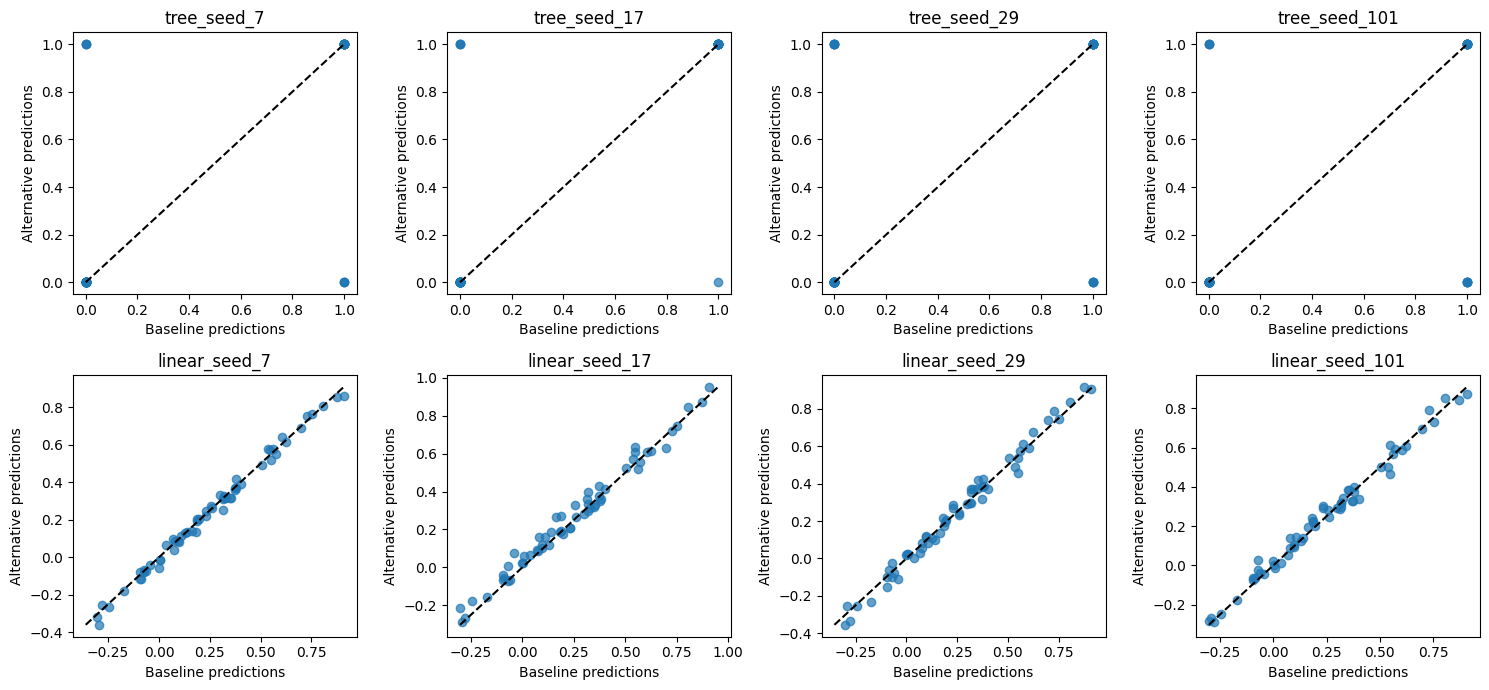

,correlation,intercept,slope,R-squared
model,,,,
tree_seed_7,0.733,0.067,0.733,0.538
tree_seed_17,0.833,0.067,0.867,0.694
tree_seed_29,0.609,0.111,0.622,0.371
tree_seed_101,0.631,0.067,0.600,0.398
linear_seed_7,0.997,-0.008,1.011,0.993
linear_seed_17,0.991,0.031,0.958,0.983
linear_seed_29,0.994,-0.008,1.037,0.987
linear_seed_101,0.993,0.015,0.971,0.987


In [ ]:
q4_results = []

fig, axes = plt.subplots(2, len(alternative_seeds), figsize=(15, 7))

for row, model_type in enumerate(["tree", "linear"]):
    baseline = predictions[f"{model_type}_seed_42"]

    for column, seed in enumerate(alternative_seeds):
        alternative_name = f"{model_type}_seed_{seed}"
        alternative = predictions[alternative_name]

        # Correlation and regression: alternative predictions on baseline predictions.
        prediction_model = LinearRegression()
        prediction_model.fit(baseline.to_frame(), alternative)

        q4_results.append({
            "model": alternative_name,
            "correlation": baseline.corr(alternative),
            "intercept": prediction_model.intercept_,
            "slope": prediction_model.coef_[0],
            "R-squared": prediction_model.score(
                baseline.to_frame(), alternative
            )
        })

        # Scatterplot.
        ax = axes[row, column]
        ax.scatter(baseline, alternative, alpha=0.7)

        low = min(baseline.min(), alternative.min())
        high = max(baseline.max(), alternative.max())
        ax.plot([low, high], [low, high], "k--")

        ax.set_title(alternative_name)
        ax.set_xlabel("Baseline predictions")
        ax.set_ylabel("Alternative predictions")

plt.tight_layout()
plt.show()

display(pd.DataFrame(q4_results).set_index("model").round(3))

### Q5 Comparing Model Stability

In [ ]:
# Compare tree depth and number of leaves.
print("Tree structures:")
display(pd.DataFrame(tree_sizes).T)

# Compare linear regression coefficients across fits.
coefficient_table = pd.DataFrame(coefficients)

print("Linear regression coefficients:")
display(coefficient_table)

print("Coefficient ranges across fits:")
display(
    pd.DataFrame({
        "minimum": coefficient_table.min(axis=1),
        "maximum": coefficient_table.max(axis=1),
        "range": coefficient_table.max(axis=1) - coefficient_table.min(axis=1)
    }).sort_values("range", ascending=False)
)

Tree structures:


,depth,leaves
tree_seed_42,8,30
tree_seed_7,8,30
tree_seed_17,8,27
tree_seed_29,8,26
tree_seed_101,7,26


Linear regression coefficients:


,linear_seed_42,linear_seed_7,linear_seed_17,linear_seed_29,linear_seed_101
age,4.590087e-03,4.459853e-03,3.571117e-03,5.121701e-03,4.081200e-03
anaemia,1.367106e-02,1.345286e-02,3.769900e-02,3.200268e-03,-1.796243e-03
creatinine_phosphokinase,4.393988e-05,4.636318e-05,4.181451e-05,2.932278e-05,4.988654e-05
diabetes,7.357562e-02,8.299436e-02,6.912868e-02,7.287827e-02,4.806677e-02
ejection_fraction,-1.038726e-02,-1.122151e-02,-1.174853e-02,-8.933575e-03,-9.151916e-03
high_blood_pressure,3.825520e-03,-2.729595e-02,-1.962671e-02,1.039235e-02,-1.472918e-03
platelets,-1.521454e-07,-1.239002e-07,-5.365539e-08,-3.561449e-07,-3.434375e-07
serum_creatinine,9.379010e-02,8.246222e-02,1.078307e-01,8.625434e-02,7.709633e-02
serum_sodium,-2.891449e-03,-3.447783e-03,1.180311e-04,-5.830626e-03,-6.469955e-03
sex,-5.732381e-02,-9.400481e-02,-4.362730e-02,-1.887148e-02,-5.827898e-02


Coefficient ranges across fits:


,minimum,maximum,range
intercept,6.858063e-01,1.619805e+00,9.339984e-01
smoking,-1.090542e-02,6.719559e-02,7.810102e-02
sex,-9.400481e-02,-1.887148e-02,7.513333e-02
anaemia,-1.796243e-03,3.769900e-02,3.949524e-02
high_blood_pressure,-2.729595e-02,1.039235e-02,3.768830e-02
diabetes,4.806677e-02,8.299436e-02,3.492759e-02
serum_creatinine,7.709633e-02,1.078307e-01,3.073433e-02
serum_sodium,-6.469955e-03,1.180311e-04,6.587986e-03
ejection_fraction,-1.174853e-02,-8.933575e-03,2.814958e-03
age,3.571117e-03,5.121701e-03,1.550584e-03


### Q6

For this dataset, I would say the statement is false for the decision trees, but true for the linear models. The tree predictions were only moderately similar across splits: their correlations ranged from 0.609 to 0.833, and their R-squared values ranged from 0.371 to 0.694. The linear model predictions were much more consistent, with correlations above 0.99 and slopes close to 1. Therefore, a model's appearance may change without greatly changing its predictions, but that was much more true for the linear models than for the trees in my results.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** ed70a927e85093c7851432f13a387ef1b58a854c
- **AI tool and model used:** ChatGPT GPT6

### *Prompts used

1. Review the Phase 1 notebook for correctness and completeness. Identify any mismatches between code, results, and written interpretation, and suggest specific improvements. Provide proposed changes in a concise numbered list.
2. Revise the solution to address the issues you found. Keep Phase 1 unchanged, include concise record of changes.

### *AI-proposed changes


1. Fix Q3 methodology: Use repeated 80/20 train/test splits of the full dataset instead of smaller subsets of the original training set, or explicitly explain the current approach.

2. Improve Q5 tree comparisons: Compare root features, split thresholds, and important decision rules, not just tree depth and leaf count.

3. Expand Q5 written interpretation: Explain how tree structures and linear regression coefficients change across seeds, and what that reveals about stability.

4. Clarify Q4 R²: Distinguish prediction-agreement R² (comparing models to each other) from test R² (comparing predictions to actual outcomes).

5. Add prediction-difference metrics: Calculate the mean absolute difference between baseline and alternative predictions to supplement correlation and R².

6. Improve Q6 conclusion: Explicitly state that linear regression is more stable than decision trees, but stability does not necessarily imply accuracy.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Modify | Keep current approach but explain why. Full re-splits would put 47 to 52 of the 60 Q2 test rows into the alternative training sets, so the Q4 comparison would be contaminated. |
| 2 | Accept | Depth and leaf counts barely changed. The top of the tree is fairly stable but there is instability further down, comparing these would improve comparisons. |
| 3 | Accept | Accepted, Q5 currently has no written explanation |
| 4 | Accept | Both used same label for different things.  |
| 5 | Accept | Tree predictions are 0/1, so mean absolute difference is the disagreement rate: 6.7 to 15%. Linear: 0.02 to 0.03. Correlation understated how similar the trees are. |
| 6 | Modify | Add that stability does not imply accuracy, and revise tree verdict to "mostly true," since the trees agree on 85 to 93% of patients. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

### Imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Q1 Load & Clean Data

In [ ]:
df = pd.read_csv("data/heart_failure/heart_failure_clinical_records_dataset.csv")

# CHANGE: standardize column names FIRST so every check below finds its column.
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

print("Missing values by column:")
display(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

binary_columns = [
    "anaemia", "diabetes", "high_blood_pressure",
    "sex", "smoking", "death_event"
]
for column in binary_columns:
    unusual_values = df.loc[~df[column].isin([0, 1]), column].unique()
    print(f"{column} values other than 0 and 1:", unusual_values)

range_checks = {
    "age": df["age"] <= 0,
    "creatinine_phosphokinase": df["creatinine_phosphokinase"] < 0,
    "ejection_fraction": ~df["ejection_fraction"].between(0, 100),
    "platelets": df["platelets"] <= 0,
    "serum_creatinine": df["serum_creatinine"] <= 0,
    "serum_sodium": df["serum_sodium"] <= 0,
    "time": df["time"] <= 0
}
for column, invalid_rows in range_checks.items():
    print(f"Rows with an unusual {column} value:", invalid_rows.sum())

for column in df.columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df = df.drop_duplicates().dropna()

X = df.drop(columns="death_event")
y = df["death_event"]

print("Cleaned dataset shape:", df.shape)
print(y.value_counts())
display(df.head())

Missing values by column:


,0
age,0
anaemia,0
creatinine_phosphokinase,0
diabetes,0
ejection_fraction,0
high_blood_pressure,0
platelets,0
serum_creatinine,0
serum_sodium,0
sex,0


Duplicate rows: 0
anaemia values other than 0 and 1: []
diabetes values other than 0 and 1: []
high_blood_pressure values other than 0 and 1: []
sex values other than 0 and 1: []
smoking values other than 0 and 1: []
death_event values other than 0 and 1: []
Rows with an unusual age value: 0
Rows with an unusual creatinine_phosphokinase value: 0
Rows with an unusual ejection_fraction value: 0
Rows with an unusual platelets value: 0
Rows with an unusual serum_creatinine value: 0
Rows with an unusual serum_sodium value: 0
Rows with an unusual time value: 0
Cleaned dataset shape: (299, 13)
death_event
0    203
1     96
Name: count, dtype: int64


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,death_event
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


### Q2 Split Data & Fit Baseline Models

In [ ]:
BASE_SEED = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=BASE_SEED, stratify=y
)

# CHANGE: store every model so Q5 can inspect structure and coefficients.
tree_models = {"tree_seed_42": DecisionTreeRegressor(random_state=BASE_SEED).fit(X_train, y_train)}
linear_models = {"linear_seed_42": LinearRegression().fit(X_train, y_train)}

predictions = pd.DataFrame(index=X_test.index)
predictions["actual"] = y_test
predictions["tree_seed_42"] = tree_models["tree_seed_42"].predict(X_test)
predictions["linear_seed_42"] = linear_models["linear_seed_42"].predict(X_test)

# CHANGE: label as "test R-squared" (predictions vs. actual outcomes).
def get_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "test R-squared": r2_score(actual, predicted)
    }

q2_results = pd.DataFrame({
    "Tree": get_metrics(y_test, predictions["tree_seed_42"]),
    "Linear regression": get_metrics(y_test, predictions["linear_seed_42"])
}).T
display(q2_results)

,MAE,RMSE,test R-squared
Tree,0.266667,0.516398,-0.232349
Linear regression,0.305999,0.384182,0.317913


### Q3 Repeat the Fits with Different Seeds

**Approach:** Each alternative model is trained on a different 80% subsample of the Q2 training set and evaluated on the same Q2 test set. A fixed test set is needed for Q4, which compares predictions on the Q2 test set. Re-splitting the full dataset would put most of those test rows into the alternative training sets (verified below), and an unpruned tree memorizes its training rows, which would distort the comparison. Trade-off: alternative models train on 191 rows instead of 239, so some variation comes from the smaller sample.

In [ ]:
alternative_seeds = [7, 17, 29, 101]
q3_results = []

for seed in alternative_seeds:
    X_alt, _, y_alt, _ = train_test_split(
        X_train, y_train, test_size=0.20, random_state=seed, stratify=y_train
    )

    tree_name = f"tree_seed_{seed}"
    linear_name = f"linear_seed_{seed}"

    tree_models[tree_name] = DecisionTreeRegressor(random_state=BASE_SEED).fit(X_alt, y_alt)
    linear_models[linear_name] = LinearRegression().fit(X_alt, y_alt)

    predictions[tree_name] = tree_models[tree_name].predict(X_test)
    predictions[linear_name] = linear_models[linear_name].predict(X_test)

    for name in [tree_name, linear_name]:
        q3_results.append({"model": name, **get_metrics(y_test, predictions[name])})

print("Training rows per alternative model:", len(X_alt))
display(pd.DataFrame(q3_results).set_index("model"))

Training rows per alternative model: 191


,MAE,RMSE,test R-squared
model,,,
tree_seed_7,0.166667,0.408248,0.229782
linear_seed_7,0.309482,0.386387,0.310061
tree_seed_17,0.233333,0.483046,-0.078306
linear_seed_17,0.314034,0.391647,0.291148
tree_seed_29,0.183333,0.428174,0.152760
linear_seed_29,0.301744,0.378238,0.338857
tree_seed_101,0.300000,0.547723,-0.386393
linear_seed_101,0.302782,0.379484,0.334496


In [ ]:
# CHANGE: verify why full re-splits were not used.
overlap = {}
for seed in alternative_seeds:
    _, X_test_resplit, _, _ = train_test_split(
        X, y, test_size=0.20, random_state=seed, stratify=y
    )
    overlap[seed] = len(X_test.index.difference(X_test_resplit.index))

pd.Series(overlap, name=f"Q2 test rows that would be in training (of {len(X_test)})")

,Q2 test rows that would be in training (of 60)
7,51
17,47
29,49
101,52


### Q4 Plot & Compare Predictions

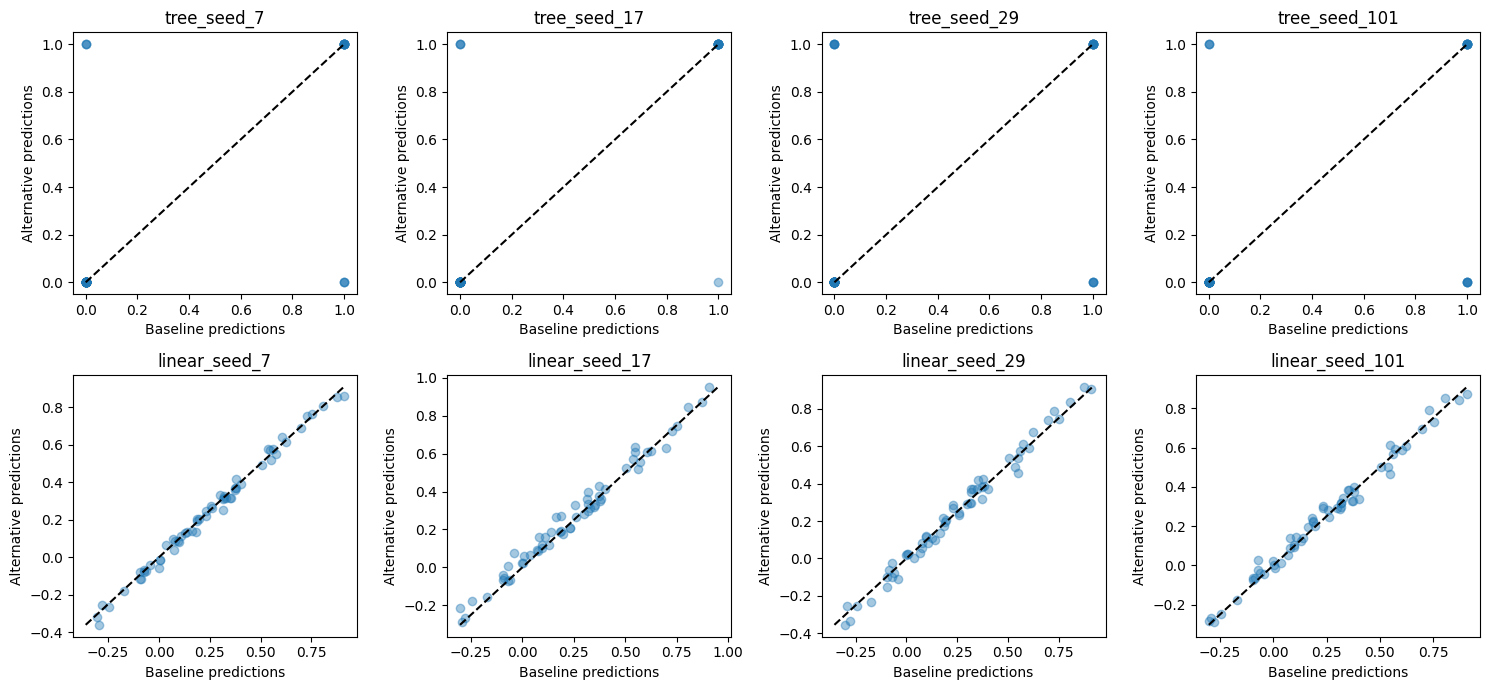

,correlation,intercept,slope,agreement R-squared,mean abs. difference
model,,,,,
tree_seed_7,0.733,0.067,0.733,0.538,0.100
tree_seed_17,0.833,0.067,0.867,0.694,0.067
tree_seed_29,0.609,0.111,0.622,0.371,0.150
tree_seed_101,0.631,0.067,0.600,0.398,0.133
linear_seed_7,0.997,-0.008,1.011,0.993,0.020
linear_seed_17,0.991,0.031,0.958,0.983,0.034
linear_seed_29,0.994,-0.008,1.037,0.987,0.031
linear_seed_101,0.993,0.015,0.971,0.987,0.027


In [ ]:
q4_results = []
fig, axes = plt.subplots(2, len(alternative_seeds), figsize=(15, 7))

for row, model_type in enumerate(["tree", "linear"]):
    baseline = predictions[f"{model_type}_seed_42"]

    for column, seed in enumerate(alternative_seeds):
        name = f"{model_type}_seed_{seed}"
        alternative = predictions[name]

        fit = LinearRegression().fit(baseline.to_frame(), alternative)

        q4_results.append({
            "model": name,
            "correlation": baseline.corr(alternative),
            "intercept": fit.intercept_,
            "slope": fit.coef_[0],
            # CHANGE: renamed; this is agreement between models, not accuracy.
            "agreement R-squared": fit.score(baseline.to_frame(), alternative),
            # CHANGE: added; for 0/1 tree predictions this is the disagreement rate.
            "mean abs. difference": (alternative - baseline).abs().mean(),
        })

        ax = axes[row, column]
        ax.scatter(baseline, alternative, alpha=0.4)
        low = min(baseline.min(), alternative.min())
        high = max(baseline.max(), alternative.max())
        ax.plot([low, high], [low, high], "k--")
        ax.set_title(name)
        ax.set_xlabel("Baseline predictions")
        ax.set_ylabel("Alternative predictions")

plt.tight_layout()
plt.show()

q4_table = pd.DataFrame(q4_results).set_index("model")
display(q4_table.round(3))

# Verification: with one predictor, agreement R-squared equals correlation squared.
assert np.allclose(q4_table["correlation"] ** 2, q4_table["agreement R-squared"])



In [ ]:
# CHANGE: tree predictions are only 0 or 1, so each scatterplot stacks onto 4 points.
# Count the combinations instead.
base = predictions["tree_seed_42"]
agreement_rows = []

for seed in alternative_seeds:
    alt = predictions[f"tree_seed_{seed}"]
    agreement_rows.append({
        "model": f"tree_seed_{seed}",
        "both 0": ((base == 0) & (alt == 0)).sum(),
        "both 1": ((base == 1) & (alt == 1)).sum(),
        "baseline 1, alt 0": ((base == 1) & (alt == 0)).sum(),
        "baseline 0, alt 1": ((base == 0) & (alt == 1)).sum(),
        "agreement rate": (base == alt).mean(),
    })

display(pd.DataFrame(agreement_rows).set_index("model").round(3))

,both 0,both 1,"baseline 1, alt 0","baseline 0, alt 1",agreement rate
model,,,,,
tree_seed_7,42,12,3,3,0.900
tree_seed_17,42,14,1,3,0.933
tree_seed_29,40,11,4,5,0.850
tree_seed_101,42,10,5,3,0.867


**a.** Linear predictions sit almost exactly on the 45° line. Tree predictions are only 0 or 1, so the scatterplots collapse onto four points. The agreement table shows the trees give the same prediction for 85 to 93% of test patients.

**b.** Linear correlations are 0.991 to 0.997. Tree correlations are lower, 0.609 to 0.833, but correlation on 0/1 predictions is pulled down sharply by a few disagreements (4 to 9 of 60 patients).

**c.** Linear: intercepts within 0.03 of zero, slopes 0.96 to 1.04, agreement R² of at least 0.98. Trees: intercepts 0.07 to 0.11, slopes 0.60 to 0.87, agreement R² 0.37 to 0.69. This R² measures agreement between two models, unlike the test R² in Q2/Q3, and here it equals correlation squared. Mean absolute difference (trees 0.07 to 0.15, linear 0.02 to 0.03) is easier to interpret.

### Q5 Comparing Model Stability

In [ ]:
# CHANGE: compare splits, not just depth and leaf count.
structure = {}
for name, model in tree_models.items():
    t = model.tree_
    left, right = t.children_left[0], t.children_right[0]
    structure[name] = {
        "depth": model.get_depth(),
        "leaves": model.get_n_leaves(),
        "root split": f"{X.columns[t.feature[0]]} <= {t.threshold[0]:.1f}",
        "left child split": X.columns[t.feature[left]] if t.feature[left] >= 0 else "leaf",
        "right child split": X.columns[t.feature[right]] if t.feature[right] >= 0 else "leaf",
        "top 3 features": ", ".join(
            pd.Series(model.feature_importances_, index=X.columns).nlargest(3).index
        ),
    }

display(pd.DataFrame(structure).T)

# CHANGE: show the top two levels of each tree's rules.
for name, model in tree_models.items():
    print(f"===== {name} =====")
    print(export_text(model, feature_names=list(X.columns), max_depth=2))

coefficient_table = pd.DataFrame({
    name: pd.Series(
        list(model.coef_) + [model.intercept_],
        index=list(X.columns) + ["intercept"]
    )
    for name, model in linear_models.items()
})
display(coefficient_table)

# CHANGE: flag coefficients whose sign flips across fits.
# Note: ranges are in raw units, so they are not comparable across features.
coefficient_summary = pd.DataFrame({
    "minimum": coefficient_table.min(axis=1),
    "maximum": coefficient_table.max(axis=1),
    "range": coefficient_table.max(axis=1) - coefficient_table.min(axis=1),
    "sign changes": (coefficient_table.min(axis=1) < 0) & (coefficient_table.max(axis=1) > 0),
}).sort_values("range", ascending=False)

display(coefficient_summary)

,depth,leaves,root split,left child split,right child split,top 3 features
tree_seed_42,8,30,time <= 73.5,serum_sodium,serum_creatinine,"time, platelets, ejection_fraction"
tree_seed_7,8,30,time <= 73.5,serum_sodium,ejection_fraction,"time, ejection_fraction, serum_creatinine"
tree_seed_17,8,27,time <= 73.5,serum_sodium,ejection_fraction,"time, ejection_fraction, serum_creatinine"
tree_seed_29,8,26,time <= 52.0,age,ejection_fraction,"time, ejection_fraction, serum_creatinine"
tree_seed_101,7,26,time <= 73.5,serum_sodium,ejection_fraction,"time, ejection_fraction, serum_creatinine"


===== tree_seed_42 =====
|--- time <= 73.50
|   |--- serum_sodium <= 136.50
|   |   |--- serum_creatinine <= 0.85
|   |   |   |--- value: [0.00]
|   |   |--- serum_creatinine >  0.85
|   |   |   |--- truncated branch of depth 3
|   |--- serum_sodium >  136.50
|   |   |--- time <= 48.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- time >  48.50
|   |   |   |--- truncated branch of depth 2
|--- time >  73.50
|   |--- serum_creatinine <= 1.45
|   |   |--- ejection_fraction <= 27.50
|   |   |   |--- truncated branch of depth 5
|   |   |--- ejection_fraction >  27.50
|   |   |   |--- truncated branch of depth 5
|   |--- serum_creatinine >  1.45
|   |   |--- ejection_fraction <= 22.50
|   |   |   |--- value: [1.00]
|   |   |--- ejection_fraction >  22.50
|   |   |   |--- truncated branch of depth 6

===== tree_seed_7 =====
|--- time <= 73.50
|   |--- serum_sodium <= 136.50
|   |   |--- ejection_fraction <= 47.50
|   |   |   |--- value: [1.00]
|   |   |--- ejection_fraction >  47

,linear_seed_42,linear_seed_7,linear_seed_17,linear_seed_29,linear_seed_101
age,4.590087e-03,4.459853e-03,3.571117e-03,5.121701e-03,4.081200e-03
anaemia,1.367106e-02,1.345286e-02,3.769900e-02,3.200268e-03,-1.796243e-03
creatinine_phosphokinase,4.393988e-05,4.636318e-05,4.181451e-05,2.932278e-05,4.988654e-05
diabetes,7.357562e-02,8.299436e-02,6.912868e-02,7.287827e-02,4.806677e-02
ejection_fraction,-1.038726e-02,-1.122151e-02,-1.174853e-02,-8.933575e-03,-9.151916e-03
high_blood_pressure,3.825520e-03,-2.729595e-02,-1.962671e-02,1.039235e-02,-1.472918e-03
platelets,-1.521454e-07,-1.239002e-07,-5.365539e-08,-3.561449e-07,-3.434375e-07
serum_creatinine,9.379010e-02,8.246222e-02,1.078307e-01,8.625434e-02,7.709633e-02
serum_sodium,-2.891449e-03,-3.447783e-03,1.180311e-04,-5.830626e-03,-6.469955e-03
sex,-5.732381e-02,-9.400481e-02,-4.362730e-02,-1.887148e-02,-5.827898e-02


,minimum,maximum,range,sign changes
intercept,6.858063e-01,1.619805e+00,9.339984e-01,False
smoking,-1.090542e-02,6.719559e-02,7.810102e-02,True
sex,-9.400481e-02,-1.887148e-02,7.513333e-02,False
anaemia,-1.796243e-03,3.769900e-02,3.949524e-02,True
high_blood_pressure,-2.729595e-02,1.039235e-02,3.768830e-02,True
diabetes,4.806677e-02,8.299436e-02,3.492759e-02,False
serum_creatinine,7.709633e-02,1.078307e-01,3.073433e-02,False
serum_sodium,-6.469955e-03,1.180311e-04,6.587986e-03,True
ejection_fraction,-1.174853e-02,-8.933575e-03,2.814958e-03,False
age,3.571117e-03,5.121701e-03,1.550584e-03,False


**Linear models:** Predictions are nearly identical across fits (correlation ≥ 0.99, mean absolute difference 0.02 to 0.03). The strongest predictors (time, ejection_fraction, serum_creatinine, age) keep the same sign and similar size. The coefficients are not fully stable, though: anaemia, high_blood_pressure, smoking and serum_sodium all change sign, which suggests their effects are weak and poorly determined. Coefficient ranges are in raw units, so they cannot be compared directly across features.

**Trees:** Summary statistics barely change (depth 7 to 8, 26 to 30 leaves), and every tree splits first on `time` (at 73.5 in four trees, 52.0 for seed 29). Below the root, though, the structure differs: the second-level splits change between serum_sodium, serum_creatinine, ejection_fraction and age, and the deeper rules differ even more. Even so, the trees agree on 85 to 93% of test predictions.

**Conclusion:** Linear models are more stable in both coefficients and predictions. Trees look more different than their predictions actually are.

### Q6

**Mostly true for this dataset.** The linear models' predictions are nearly identical even where weak coefficients flip sign. The trees differ visibly below the root split, yet they classify 85 to 93% of test patients the same way. Their correlations (0.61 to 0.83) understate this, because correlation is very sensitive to a few disagreements on 0/1 predictions.

Two caveats. First, 4 to 9 of 60 patients still get a different tree prediction, which matters if the model is used for individual decisions. Second, stability does not imply accuracy: the linear models are the most stable but explain only about 30% of test variance (test R² 0.29 to 0.34). Tree test R² swings from −0.39 to 0.23 across fits, although the trees often have a lower MAE.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The biggest improvements were in questions 4, 5 and 6. We renamed the R 2 in Q4 to “agreement R-squared” to distinguish it from test R 2 and added the mean absolute difference between predictions. As the tree predictions are just 0 or 1, this number is simply the disagreement rate and it revealed that correlation made the trees appear less similar to each other than they actually were. In Q5 we compared root split, child splits and top rules rather than just depth and leaf count and wrote an explanation for it. Q6 The upgrade was changing the tree verdict to “mostly true,” adding that stability doesn’t mean accuracy.

One big mistake the AI made. It said to re-split the full dataset in Q3 but that would have put 47 to 52 of the 60 test rows into the alternative training sets which would have messed up the Q4 comparison.

The entire solution was run top to bottom to ensure that each cell worked. The Q3 overlap test confirmed the decision not to re-split the full data, the R² of agreement in Q4 matched correlation squared, and the numbers in our written answers matched the output tables.

There are still some concerns. Since the test set is only 60 rows, a 6.7 to 15% disagreement rate is only a few patients. The tree scatterplots were not very useful, since the points stack up in four places, so we used a counts table instead.